In [45]:
import glob
import os
import random

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from tqdm.notebook import tqdm
from ot import sliced_wasserstein_distance

from cluster_weather_years.functions import (
    build_df_centroids,
    build_df_random,
    standardize_df,
)

from cluster_weather_years.constants import (
    BASE_OUTPUT,
    HYDROLOGICAL_YEARS,
    COUNTRIES,
    SEASONS,
)

In [58]:
countries = ["NL"]
vars_to_match = ["NL_GHI", "NL_TA", "NL_WS"]

In [59]:
# Config
NUM_CLUSTERS = 30  # hardcode
NUM_CLUSTERS_LARGE_SMALL = 5  # hardcode, 30 years if main one is 5y and vice versa

# RUN_ID_MAIN = "NL_20251024_1320"  # NL, 30 years
# LABEL_RUN_ID_MAIN = "SA, NL 30y"
RUN_ID_MAIN = "NL_20251112_1638"  # NL, 30y seasonal, incl. residual load
LABEL_RUN_ID_MAIN = "Seasonal SA + RL, NL 30y"
LABEL_RUN_ID_MAIN_RANDOM = "Random 30y"
# RUN_ID = "NL_20251023_0942"  # NL, 5 years
# RUN_ID_alternative = "NL_20251024_1320_5y_subset"  # 5y subsample from 30y sample
RUN_ID_alternative = "NL_20251111_1601"  # NL, 30y, seasonal_wasserstein
LABEL_RUN_ID_ALTERNATIVE = "Seasonal SA, NL 30y"

# RUN_ID_LARGE_SMALL = "NL_20251024_1320"  # 30 years if main one is 5y and vice versa
RUN_ID_LARGE_SMALL = "NL_20251023_0942"  # 30 years if main one is 5y and vice versa
LABEL_RUN_ID_LARGE_SMALL = "SA, NL 5y subset"
LABEL_RUN_ID_LARGE_SMALL_RANDOM = "Random 5y subset"

FNAME_KMEDOIDS = "centroid_years_load_30yr.csv"  # K-medoids run to compare to
FNAME_KMEDOIDS_LARGE_SMALL = (
    "centroid_years_load.csv"  # 5yr K-medoids run if main one is 30y and vice versa
)
LABEL_KMEDOIDS = "K-medoids, NL 30y"

LABEL_MLZ = "MLZ-25 36y"

seed = 42
random.seed(seed)

In [60]:
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")


In [61]:
# build df with all models
PATH = (
    "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/pecd_data/climate/"
)
# MODELS = ["AWI-_AWCM", "BCC-_BCCS", "CMCC_CMR5", "ECEC_ECE3", "MPI-_MEHR", "MRI-_MRM2"]
MODEL_MAPPING = {
    "AWI-_AWCM": "awi_cm_1_1_mr",
    "BCC-_BCCS": "bcc_csm2_mr",
    "CMCC_CMR5": "cmcc_cm2_sr5",
    "ECEC_ECE3": "ec_earth3",
    "MPI-_MEHR": "mpi_esm1_2_hr",
    "MRI-_MRM2": "mri_esm2_0",
}

vars = ["GHI", "TA", "WS"]

df_daily_vars = {}
# for country in countries:
country = countries[0]
for var in vars:
    df_daily_vars[var] = []
    for model_key, model_value in MODEL_MAPPING.items():
        all_model_files = glob.glob(
            os.path.join(PATH, f"P_CMI6_{model_key}_{var}*.csv")
        )
        df_model = pd.concat(
            (pd.read_csv(f, header=52) for f in all_model_files), ignore_index=True
        )
        df_model["Date"] = pd.to_datetime(df_model["Date"])
        df_model_daily = (
            df_model.groupby([pd.Grouper(key="Date", freq="D")])
            .mean(numeric_only=True)
            .reset_index()
            .sort_values(["Date"])
        )
        df_model_daily["model"] = model_value
        df_daily_vars[var].append(
            df_model_daily[["Date", "model", country]].rename(
                columns={country: f"{country}_{var}"}
            )
        )
    df_daily_vars[var] = pd.concat(df_daily_vars[var], ignore_index=True)

df_daily = (
    df_daily_vars["GHI"]
    .merge(df_daily_vars["TA"], on=["Date", "model"])
    .merge(df_daily_vars["WS"], on=["Date", "model"])
)

df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily["Hydrological_year"] = (
    df_daily["Date"] - pd.DateOffset(months=3)
).dt.year  # start hydrological year 1st of April

df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")
df_std = standardize_df(df_daily, vars_to_match)


In [62]:
# settings for random-draws
df_idx = df_std.set_index(["model", "Hydrological_year"]).sort_index()
keys = df_idx.index.unique().to_numpy()
rng = np.random.default_rng(seed)

In [63]:
df_selections_main = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_MAIN}/results_grid.csv"), index_col=0
)

df_sel_main = df_selections_main.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

In [64]:
# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_main)):
    datasets[f"{LABEL_RUN_ID_MAIN} {i + 1}"] = build_df_centroids(
        df_std, eval(df_sel_main.iloc[i]["selected"])
    )

    datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS
    )

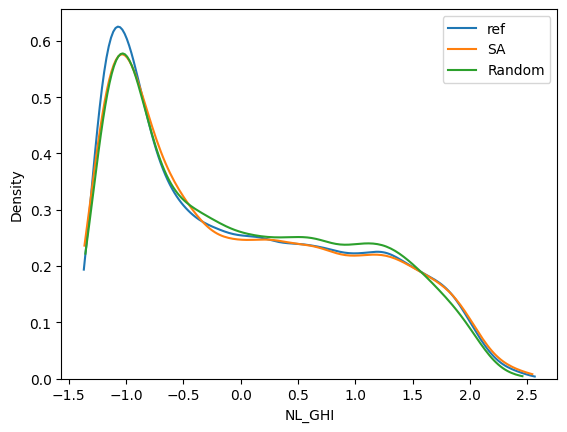

In [65]:
sns.kdeplot(df_std["NL_GHI"], cut=0, label="ref")
sns.kdeplot(datasets["Seasonal SA + RL, NL 30y 1"]["NL_GHI"], cut=0, label="SA")
sns.kdeplot(datasets["Random 30y 1"]["NL_GHI"], cut=0, label="Random")
plt.legend()

In [66]:
ds_ref = df_std[vars_to_match].to_numpy()

df_wasserstein = pd.DataFrame(index=datasets.keys(), columns=["Wasserstein_distance"])
for dataset in tqdm(datasets):
    ds_sel = datasets[dataset][vars_to_match].to_numpy()
    df_wasserstein.loc[dataset, "Wasserstein_distance"] = sliced_wasserstein_distance(
        ds_sel, ds_ref, seed=seed, n_projections=50
    )

df_wasserstein["dataset_type"] = (
    df_wasserstein.index.to_series()
    .str.replace(r"\s*\d+\s*$", "", regex=True)
    .str.strip()
)

  0%|          | 0/90 [00:00<?, ?it/s]

In [67]:
np.shape(ds_ref)

(63558, 3)

<Axes: ylabel='Wasserstein_distance'>

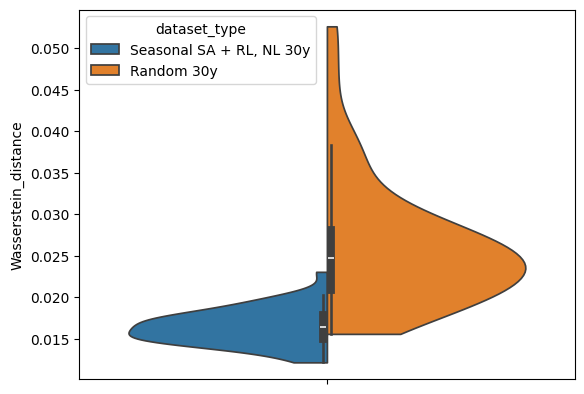

In [68]:
sns.violinplot(
    data=df_wasserstein,
    # x="variable",
    y="Wasserstein_distance",
    hue="dataset_type",
    split=True,
    cut=0,
)